# Diabetes Prediction using Machine Learning

Classification model to predict whether a patient is likely to have diabetes, built with Python, Pandas and Scikit-learn.

## Setup

Run the cells below. When prompted, upload `diabetes.csv`.

In [1]:
# Core libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings, os

# Scikit-learn
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             roc_auc_score, roc_curve)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# Upload diabetes.csv (Colab only). Skipped if the file already exists.
DATA_PATH = "diabetes.csv"

if not os.path.exists(DATA_PATH):
    try:
        from google.colab import files
        uploaded = files.upload()
        DATA_PATH = list(uploaded.keys())[0]
    except ImportError:
        raise FileNotFoundError("diabetes.csv not found. Place it in the working directory.")

print("Using dataset:", DATA_PATH)

Saving diabetes.csv to diabetes.csv
Using dataset: diabetes.csv


---
# Part 1 — Data Preparation

## 1.1 Load the dataset

In [3]:
df = pd.read_csv(DATA_PATH)
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## 1.2 Explore the dataset

### a. Shape, b. Column names, c. Data types

In [4]:
print("Shape of dataset (rows, columns):", df.shape)
print("\nColumn names:")
print(list(df.columns))
print("\nData types:")
print(df.dtypes)

Shape of dataset (rows, columns): (768, 9)

Column names:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

Data types:
Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


### d. Missing values

`isnull()` shows no missing values, but zeros in `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin` and `BMI` are physiologically impossible — they are missing values recorded as 0 and must be handled.

In [6]:
print("Explicit missing values (NaN) per column:")
print(df.isnull().sum())

zero_invalid_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

zero_counts = (df[zero_invalid_cols] == 0).sum()
zero_pct = (zero_counts / len(df) * 100).round(2)
hidden_missing = pd.DataFrame({"Zero count": zero_counts, "Percent of rows": zero_pct})
print("\nHidden missing values (zeros in columns where 0 is impossible):")
hidden_missing

Explicit missing values (NaN) per column:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Hidden missing values (zeros in columns where 0 is impossible):


,Zero count,Percent of rows
Glucose,5,0.65
BloodPressure,35,4.56
SkinThickness,227,29.56
Insulin,374,48.70
BMI,11,1.43


### e. Basic statistical summary

In [7]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.85,3.37,0.00,1.00,3.00,6.00,17.00
Glucose,768.0,120.89,31.97,0.00,99.00,117.00,140.25,199.00
BloodPressure,768.0,69.11,19.36,0.00,62.00,72.00,80.00,122.00
SkinThickness,768.0,20.54,15.95,0.00,0.00,23.00,32.00,99.00
Insulin,768.0,79.80,115.24,0.00,0.00,30.50,127.25,846.00
BMI,768.0,31.99,7.88,0.00,27.30,32.00,36.60,67.10
DiabetesPedigreeFunction,768.0,0.47,0.33,0.08,0.24,0.37,0.63,2.42
Age,768.0,33.24,11.76,21.00,24.00,29.00,41.00,81.00
Outcome,768.0,0.35,0.48,0.00,0.00,0.00,1.00,1.00


### Target variable distribution

         Count  Percent
Outcome                
0          500     65.1
1          268     34.9


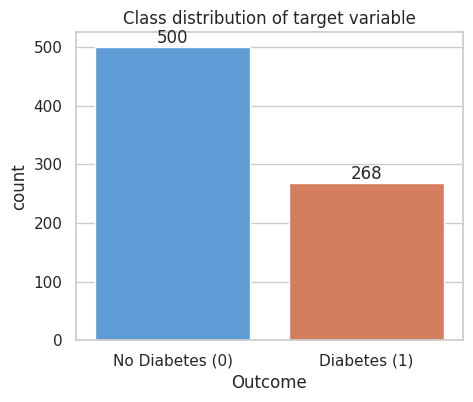

In [8]:
outcome_counts = df["Outcome"].value_counts()
outcome_pct = (outcome_counts / len(df) * 100).round(1)
print(pd.DataFrame({"Count": outcome_counts, "Percent": outcome_pct}))

plt.figure(figsize=(5, 4))
ax = sns.countplot(x="Outcome", data=df, palette=["#4C9BE8", "#E8744C"])
ax.set_xticklabels(["No Diabetes (0)", "Diabetes (1)"])
ax.set_title("Class distribution of target variable")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.show()

### Feature distributions and relationship with the target

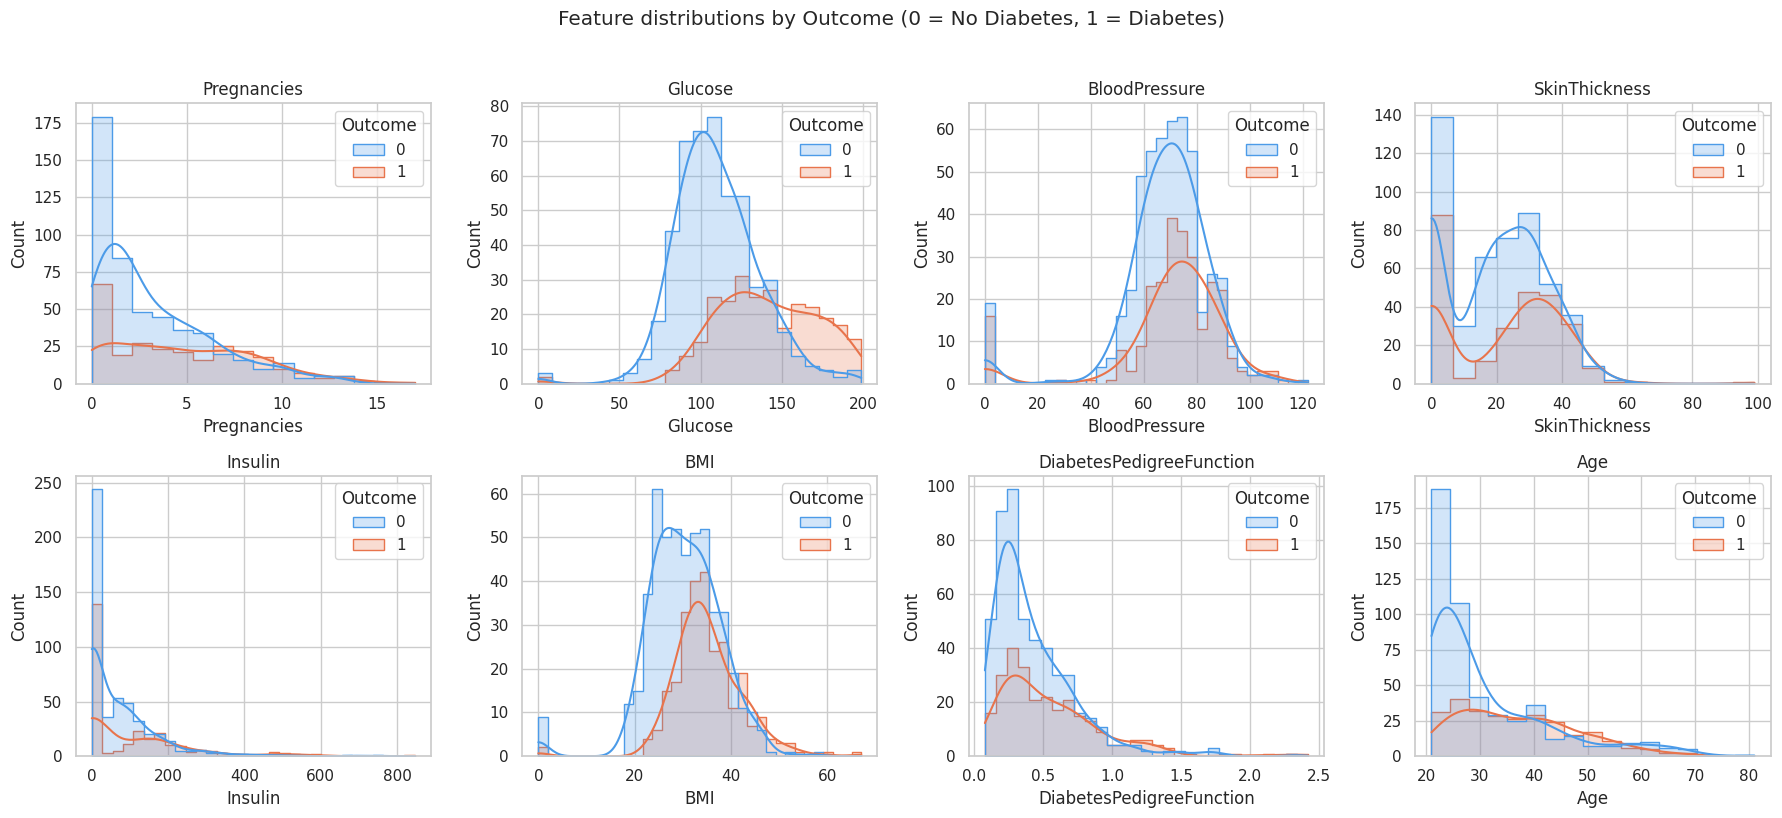

In [9]:
features = [c for c in df.columns if c != "Outcome"]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), features):
    sns.histplot(data=df, x=col, hue="Outcome", kde=True, ax=ax, element="step",
                 palette=["#4C9BE8", "#E8744C"])
    ax.set_title(col)
plt.suptitle("Feature distributions by Outcome (0 = No Diabetes, 1 = Diabetes)", y=1.02)
plt.tight_layout()
plt.show()

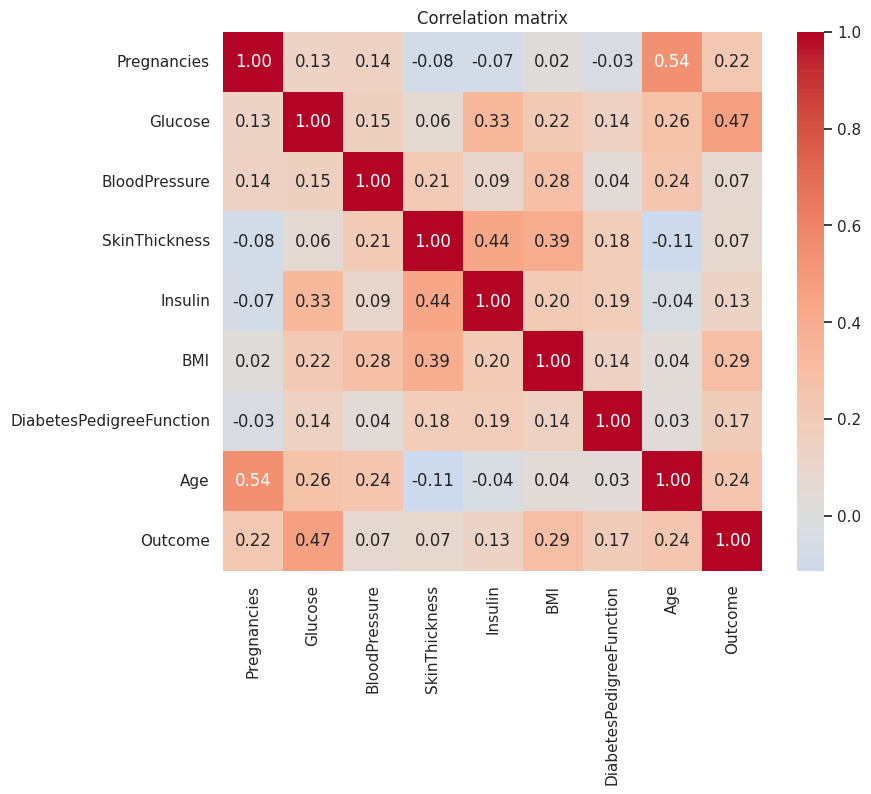

Correlation of each feature with Outcome:
Glucose                     0.467
BMI                         0.293
Age                         0.238
Pregnancies                 0.222
DiabetesPedigreeFunction    0.174
Insulin                     0.131
SkinThickness               0.075
BloodPressure               0.065
Name: Outcome, dtype: float64


In [10]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation matrix")
plt.show()

print("Correlation of each feature with Outcome:")
print(df.corr()["Outcome"].drop("Outcome").sort_values(ascending=False).round(3))

### Dataset exploration summary

- 768 rows × 9 columns; all numeric (7 int, 2 float); no categorical features.
- No explicit NaNs, but hidden missing values as zeros: `Insulin` ~49%, `SkinThickness` ~30%, `BloodPressure` ~5%, `BMI` ~1%, `Glucose` <1%.
- Target imbalance: 500 No Diabetes (65%) vs 268 Diabetes (35%).
- Strongest correlation with `Outcome`: `Glucose` (0.47), `BMI` (0.29), `Age` (0.24).

### Features and target

**Features (X):** `Pregnancies`, `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, `BMI`, `DiabetesPedigreeFunction`, `Age` — eight numeric medical attributes.
**Target (y):** `Outcome` — 0 = No Diabetes, 1 = Diabetes.

## 1.3 Separate features (X) and target (y)

In [11]:
X = df.drop(columns="Outcome")
y = df["Outcome"]

print("Features (X) shape:", X.shape)
print("Target (y) shape:  ", y.shape)
print("\nFeature columns:", list(X.columns))

Features (X) shape: (768, 8)
Target (y) shape:   (768,)

Feature columns: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']


## 1.4 Train-Test Split

80/20 split, stratified on `Outcome` so both sets keep the same class ratio.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print(f"Training set: {X_train.shape[0]} rows, {X_train.shape[1]} features")
print(f"Testing set:  {X_test.shape[0]} rows, {X_test.shape[1]} features")
print("\nClass balance in training set:")
print(y_train.value_counts(normalize=True).round(3))
print("\nClass balance in testing set:")
print(y_test.value_counts(normalize=True).round(3))

Training set: 614 rows, 8 features
Testing set:  154 rows, 8 features

Class balance in training set:
Outcome
0    0.651
1    0.349
Name: proportion, dtype: float64

Class balance in testing set:
Outcome
0    0.649
1    0.351
Name: proportion, dtype: float64


## 1.5 Preprocessing

**Steps performed**
- **Missing values:** impossible zeros → `NaN` → median imputation (median chosen because columns such as `Insulin` are skewed).
- **Categorical encoding:** not needed, all features are numeric.
- **Scaling:** `StandardScaler` (zero mean, unit variance), since Logistic Regression is sensitive to feature scale.

Imputer and scaler are fitted on the training set only and applied to the test set, to avoid data leakage.

In [13]:
# Step a: replace impossible zeros with NaN so the imputer can handle them
X_train_clean = X_train.copy()
X_test_clean = X_test.copy()
X_train_clean[zero_invalid_cols] = X_train_clean[zero_invalid_cols].replace(0, np.nan)
X_test_clean[zero_invalid_cols] = X_test_clean[zero_invalid_cols].replace(0, np.nan)

print("Missing values in training set after marking zeros as NaN:")
print(X_train_clean.isnull().sum())

Missing values in training set after marking zeros as NaN:
Pregnancies                   0
Glucose                       4
BloodPressure                23
SkinThickness               175
Insulin                     290
BMI                           9
DiabetesPedigreeFunction      0
Age                           0
dtype: int64


In [14]:
# Steps a + c as reusable preprocessing (fit on train only, applied to test)
preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

X_train_prep = preprocessor.fit_transform(X_train_clean)
X_test_prep = preprocessor.transform(X_test_clean)

print("Medians used for imputation (learned from training data):")
print(pd.Series(preprocessor.named_steps["imputer"].statistics_, index=X.columns).round(2))

print("\nMissing values after imputation — train:", np.isnan(X_train_prep).sum(),
      "| test:", np.isnan(X_test_prep).sum())

print("\nTraining features after scaling (mean ≈ 0, std ≈ 1):")
pd.DataFrame(X_train_prep, columns=X.columns).describe().loc[["mean", "std"]].round(3)

Medians used for imputation (learned from training data):
Pregnancies                   3.00
Glucose                     117.00
BloodPressure                72.00
SkinThickness                29.00
Insulin                     125.00
BMI                          32.40
DiabetesPedigreeFunction      0.38
Age                          29.00
dtype: float64

Missing values after imputation — train: 0 | test: 0

Training features after scaling (mean ≈ 0, std ≈ 1):


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
mean,-0.000,-0.000,0.000,-0.000,-0.000,0.000,-0.000,-0.000
std,1.001,1.001,1.001,1.001,1.001,1.001,1.001,1.001


---
# Part 2 — Machine Learning Model Building

## 2.1 Libraries

All required libraries (`LogisticRegression`, `Pipeline`, `SimpleImputer`, `StandardScaler`, metrics) were imported in the Setup section above.

## 2.2 Selected algorithm: Logistic Regression

The model is built as a single `Pipeline` so that preprocessing and classification always travel together — the same object can later be used to score new patients safely.

In [15]:
log_reg_model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])

log_reg_model

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('classifier',
                 LogisticRegression(max_iter=1000, random_state=42))])

## 2.3 Why Logistic Regression is suitable for this problem

- The target is binary (0/1), which is exactly what Logistic Regression models — it outputs *P(Diabetes | features)*.
- It gives a probability (risk score), not just a label, which is useful in a medical setting and lets the decision threshold be tuned.
- It is interpretable: each coefficient shows how a feature raises or lowers the odds of diabetes.
- The dataset is small (768 rows, 8 numeric features), so a low-variance linear model is less likely to overfit than a complex one.
- It is the standard baseline for tabular classification; a Random Forest is trained later only to check whether a non-linear model adds anything.

---
# Part 3 — Model Training

## 3.1 Fit the model on the training dataset

In [16]:
log_reg_model.fit(X_train_clean, y_train)
print("Model training complete.")

clf = log_reg_model.named_steps["classifier"]
print("\nIntercept:", clf.intercept_.round(4))
print("\nLearned coefficients (on standardized features):")
coef_table = pd.DataFrame({"Feature": X.columns,
                           "Coefficient": clf.coef_[0].round(4),
                           "Odds ratio (e^coef)": np.exp(clf.coef_[0]).round(3)})
coef_table.sort_values("Coefficient", ascending=False).reset_index(drop=True)

Model training complete.

Intercept: [-0.8722]

Learned coefficients (on standardized features):


,Feature,Coefficient,Odds ratio (e^coef)
0,Glucose,1.1826,3.263
1,BMI,0.6887,1.991
2,Pregnancies,0.3774,1.459
3,DiabetesPedigreeFunction,0.2333,1.263
4,Age,0.1478,1.159
5,SkinThickness,0.0283,1.029
6,BloodPressure,-0.0441,0.957
7,Insulin,-0.0661,0.936


## 3.2 Predictions on the training dataset

In [17]:
y_train_pred = log_reg_model.predict(X_train_clean)
y_train_proba = log_reg_model.predict_proba(X_train_clean)[:, 1]

print("First 15 training predictions vs actual:")
pd.DataFrame({"Actual": y_train.values[:15],
              "Predicted": y_train_pred[:15],
              "P(Diabetes)": y_train_proba[:15].round(3)})

First 15 training predictions vs actual:


,Actual,Predicted,P(Diabetes)
0,0,0,0.049
1,0,0,0.325
2,0,0,0.161
3,0,0,0.393
4,0,0,0.220
5,1,1,0.845
6,1,0,0.372
7,1,1,0.919
8,0,0,0.030
9,0,0,0.032


## 3.3 Training accuracy

In [18]:
train_accuracy = accuracy_score(y_train, y_train_pred)
print(f"Training accuracy: {train_accuracy:.4f}  ({train_accuracy*100:.2f}%)")

print("\nTraining confusion matrix:")
print(confusion_matrix(y_train, y_train_pred))

Training accuracy: 0.7964  (79.64%)

Training confusion matrix:
[[362  38]
 [ 87 127]]


---
# Part 4 — Model Performance Analysis

## 4.1 Predictions and accuracy on the test dataset

In [19]:
y_test_pred = log_reg_model.predict(X_test_clean)
y_test_proba = log_reg_model.predict_proba(X_test_clean)[:, 1]

test_accuracy = accuracy_score(y_test, y_test_pred)
print(f"Test accuracy: {test_accuracy:.4f}  ({test_accuracy*100:.2f}%)")

Test accuracy: 0.7078  (70.78%)


## 4.2 Precision, Recall and F1-Score

Positive class = 1 (Diabetes). Precision: of patients flagged diabetic, how many truly are. Recall: of true diabetics, how many were caught. F1: harmonic mean of the two.

In [20]:
test_precision = precision_score(y_test, y_test_pred)
test_recall = recall_score(y_test, y_test_pred)
test_f1 = f1_score(y_test, y_test_pred)
test_auc = roc_auc_score(y_test, y_test_proba)

print(f"Precision (class 1): {test_precision:.4f}")
print(f"Recall    (class 1): {test_recall:.4f}")
print(f"F1-Score  (class 1): {test_f1:.4f}")
print(f"ROC-AUC            : {test_auc:.4f}")

print("\nFull classification report:")
print(classification_report(y_test, y_test_pred, target_names=["No Diabetes (0)", "Diabetes (1)"]))

Precision (class 1): 0.6000
Recall    (class 1): 0.5000
F1-Score  (class 1): 0.5455
ROC-AUC            : 0.8130

Full classification report:
                 precision    recall  f1-score   support

No Diabetes (0)       0.75      0.82      0.78       100
   Diabetes (1)       0.60      0.50      0.55        54

       accuracy                           0.71       154
      macro avg       0.68      0.66      0.67       154
   weighted avg       0.70      0.71      0.70       154



## 4.3 Confusion Matrix

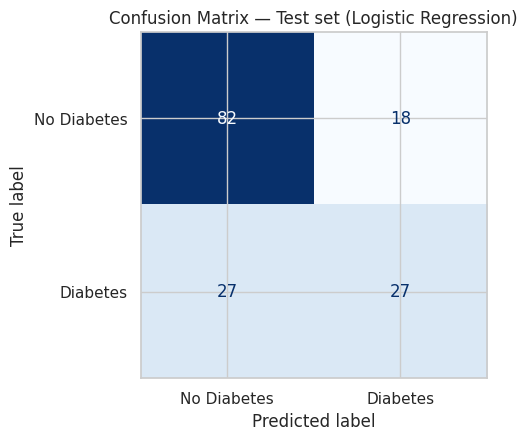

True Negatives  (TN): 82  — healthy patients correctly identified
False Positives (FP): 18  — healthy patients wrongly flagged as diabetic
False Negatives (FN): 27  — diabetic patients missed by the model
True Positives  (TP): 27  — diabetic patients correctly identified

Specificity (TN rate): 0.8200
Sensitivity (Recall) : 0.5000


In [21]:
cm = confusion_matrix(y_test, y_test_pred)
tn, fp, fn, tp = cm.ravel()

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(cm, display_labels=["No Diabetes", "Diabetes"]).plot(
    cmap="Blues", ax=ax, colorbar=False)
ax.set_title("Confusion Matrix — Test set (Logistic Regression)")
plt.show()

print(f"True Negatives  (TN): {tn}  — healthy patients correctly identified")
print(f"False Positives (FP): {fp}  — healthy patients wrongly flagged as diabetic")
print(f"False Negatives (FN): {fn}  — diabetic patients missed by the model")
print(f"True Positives  (TP): {tp}  — diabetic patients correctly identified")
print(f"\nSpecificity (TN rate): {tn/(tn+fp):.4f}")
print(f"Sensitivity (Recall) : {tp/(tp+fn):.4f}")

## 4.4 ROC curve

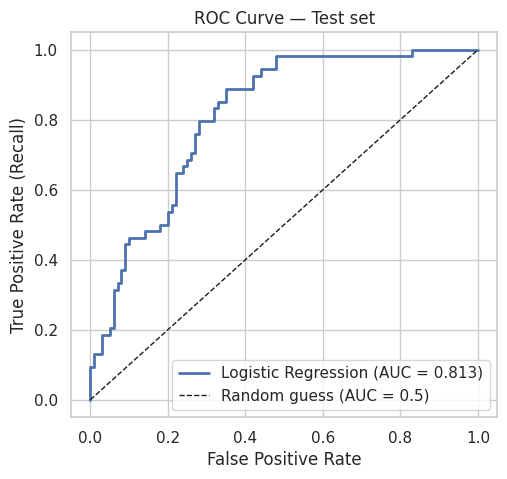

In [22]:
fpr, tpr, _ = roc_curve(y_test, y_test_proba)

plt.figure(figsize=(5.5, 5))
plt.plot(fpr, tpr, lw=2, label=f"Logistic Regression (AUC = {test_auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1, label="Random guess (AUC = 0.5)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve — Test set")
plt.legend(loc="lower right")
plt.show()

## 4.5 Comparison of training vs. testing performance

In [23]:
def metric_row(y_true, y_pred, y_proba):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1-Score": f1_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_proba),
    }

comparison = pd.DataFrame({
    "Training": metric_row(y_train, y_train_pred, y_train_proba),
    "Testing": metric_row(y_test, y_test_pred, y_test_proba),
}).T
comparison.loc["Gap (Train − Test)"] = comparison.loc["Training"] - comparison.loc["Testing"]
comparison.round(4)

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Training,0.7964,0.7697,0.5935,0.6702,0.8502
Testing,0.7078,0.6000,0.5000,0.5455,0.8130
Gap (Train − Test),0.0886,0.1697,0.0935,0.1247,0.0372


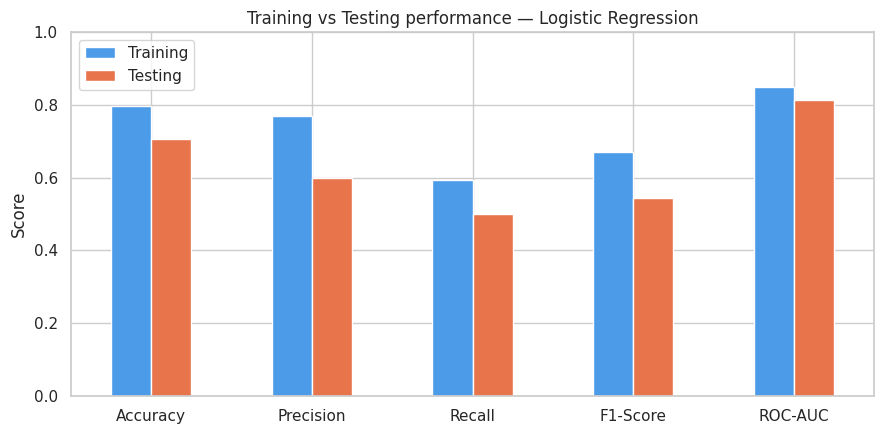

In [24]:
comparison.drop(index="Gap (Train − Test)").T.plot(kind="bar", figsize=(9, 4.5),
                                                      color=["#4C9BE8", "#E8744C"], rot=0)
plt.ylim(0, 1)
plt.title("Training vs Testing performance — Logistic Regression")
plt.ylabel("Score")
plt.legend(title="")
plt.tight_layout()
plt.show()

### Cross-validation

5-fold stratified CV on the training data gives a more reliable estimate than a single split.

In [25]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = cross_val_score(log_reg_model, X_train_clean, y_train, cv=cv, scoring="accuracy")

print("5-fold CV accuracy per fold:", cv_scores.round(4))
print(f"Mean CV accuracy: {cv_scores.mean():.4f}  (± {cv_scores.std():.4f})")

5-fold CV accuracy per fold: [0.7886 0.7886 0.8211 0.7805 0.7623]
Mean CV accuracy: 0.7882  (± 0.0191)


## 4.6 Feature importance

Features are standardized, so coefficient magnitudes are comparable. Positive → higher diabetes risk.

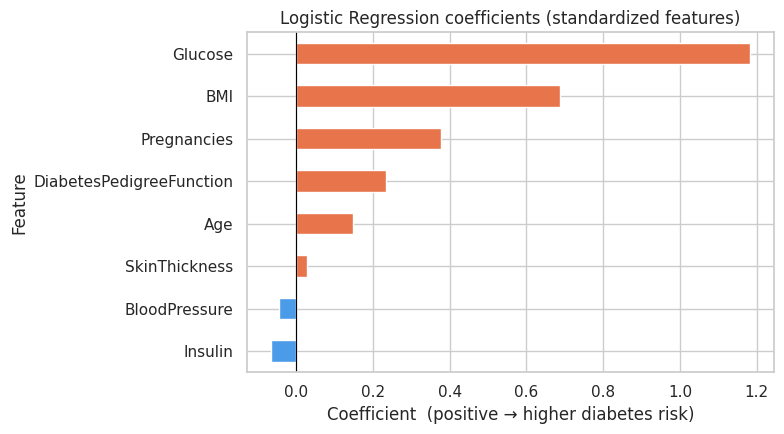

,Feature,Coefficient,Odds ratio (e^coef)
0,Glucose,1.1826,3.263
1,BMI,0.6887,1.991
2,Pregnancies,0.3774,1.459
3,DiabetesPedigreeFunction,0.2333,1.263
4,Age,0.1478,1.159
5,SkinThickness,0.0283,1.029
6,BloodPressure,-0.0441,0.957
7,Insulin,-0.0661,0.936


In [26]:
coef_sorted = coef_table.set_index("Feature")["Coefficient"].sort_values()

plt.figure(figsize=(8, 4.5))
colors = ["#E8744C" if v > 0 else "#4C9BE8" for v in coef_sorted]
coef_sorted.plot(kind="barh", color=colors)
plt.axvline(0, color="black", lw=0.8)
plt.title("Logistic Regression coefficients (standardized features)")
plt.xlabel("Coefficient  (positive → higher diabetes risk)")
plt.tight_layout()
plt.show()

coef_table.sort_values("Coefficient", ascending=False).reset_index(drop=True)

## 4.7 Comparison with a non-linear model (Random Forest)

In [27]:
rf_model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(n_estimators=300, max_depth=6,
                                          random_state=RANDOM_STATE)),
])
rf_model.fit(X_train_clean, y_train)

rf_train_pred = rf_model.predict(X_train_clean)
rf_test_pred = rf_model.predict(X_test_clean)
rf_train_proba = rf_model.predict_proba(X_train_clean)[:, 1]
rf_test_proba = rf_model.predict_proba(X_test_clean)[:, 1]

model_comparison = pd.DataFrame({
    "LogReg — Train": metric_row(y_train, y_train_pred, y_train_proba),
    "LogReg — Test": metric_row(y_test, y_test_pred, y_test_proba),
    "RandomForest — Train": metric_row(y_train, rf_train_pred, rf_train_proba),
    "RandomForest — Test": metric_row(y_test, rf_test_pred, rf_test_proba),
}).T
model_comparison.round(4)

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
LogReg — Train,0.7964,0.7697,0.5935,0.6702,0.8502
LogReg — Test,0.7078,0.6000,0.5000,0.5455,0.8130
RandomForest — Train,0.8860,0.9091,0.7477,0.8205,0.9632
RandomForest — Test,0.7338,0.6512,0.5185,0.5773,0.8083


## 4.8 Interpretation of the model results

- **Test performance:** ≈ 71% accuracy, ROC-AUC ≈ 0.81 (baseline of always predicting "No Diabetes" = 65%).
- **Train vs. test:** ≈ 80% vs ≈ 71% accuracy. Cross-validation gives ≈ 79%, so this test split is a hard one and the gap reflects mild overfitting only. The Random Forest overfits far more (≈ 89% train vs ≈ 73% test) without a better test AUC.
- **Precision 0.60 vs recall 0.50:** the model misses half of true diabetics (27 FN), a typical effect of class imbalance at the 0.5 threshold.
- **Key drivers:** `Glucose` (≈ 3.3× odds per standard deviation), then `BMI`, `Pregnancies`, `DiabetesPedigreeFunction`, `Age`. `BloodPressure`, `SkinThickness`, `Insulin` add little.

## 4.9 Conclusions

1. Logistic Regression is a sufficient and interpretable model; the more complex Random Forest does not generalise better.
2. Glucose and BMI are the key risk indicators for screening.
3. Recall should be improved for screening use; `class_weight="balanced"` raises it to ≈ 0.70 (appendix).
4. Missing data (`Insulin`, `SkinThickness`) is the main limitation; next steps are threshold tuning, hyperparameter search and external validation.

## Appendix — Logistic Regression with `class_weight="balanced"`

In [28]:
balanced_model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced",
                                      random_state=RANDOM_STATE)),
])
balanced_model.fit(X_train_clean, y_train)
bal_pred = balanced_model.predict(X_test_clean)
bal_proba = balanced_model.predict_proba(X_test_clean)[:, 1]

pd.DataFrame({
    "Default LogReg (threshold 0.5)": metric_row(y_test, y_test_pred, y_test_proba),
    "Balanced LogReg": metric_row(y_test, bal_pred, bal_proba),
}).T.round(4)

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Default LogReg (threshold 0.5),0.7078,0.6000,0.5000,0.5455,0.8130
Balanced LogReg,0.7338,0.6032,0.7037,0.6496,0.8126


---
**End of assignment.**